In [4]:
import pickle
import matplotlib.pyplot  as plt
DATA_PATH = "RML2016.10a_dict.pkl"

with open(DATA_PATH, "rb") as f:
    data = pickle.load(f, encoding="latin1")

print(type(data))
print(len(data))

first_key = list(data.keys())[0]
print(first_key)
print(type(first_key))

<class 'dict'>
220
('QPSK', 2)
<class 'tuple'>


In [5]:
mod_types = sorted(set(k[0] for k in data.keys()))
snr_levels = sorted(set(k[1] for k in data.keys()))

print(mod_types)
print(snr_levels)

['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
[-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]


In [6]:
example_array = data[('QPSK', 2)]
print(example_array.shape)

(1000, 2, 128)


In [7]:
example = example_array[0]
print(example.shape)

I = example[0]
Q = example[1]
print(I.shape)
print(Q.shape)

(2, 128)
(128,)
(128,)


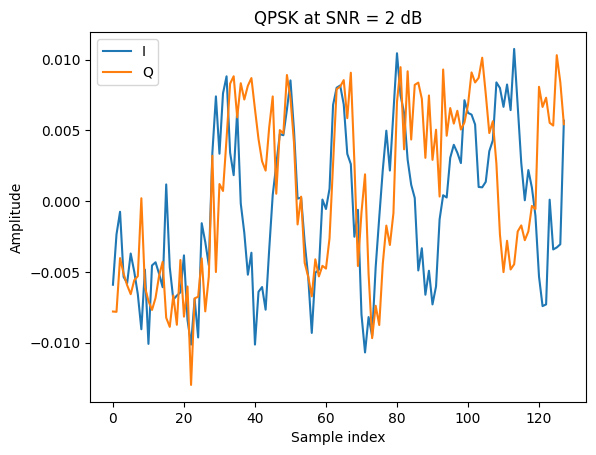

In [8]:
plt.plot(I, label="I")
plt.plot(Q, label="Q")
plt.xlabel("Sample index")
plt.ylabel("Amplitude")
plt.title("QPSK at SNR = 2 dB")
plt.legend()
plt.show()

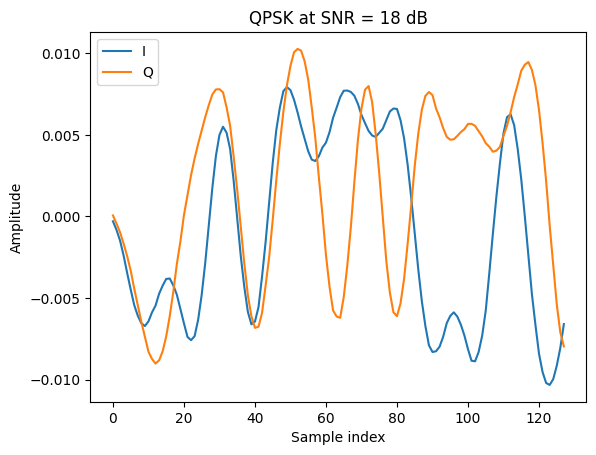

In [9]:
example_array_highsnr = data[('QPSK', 18)]
example_hs = example_array_highsnr[0]
I_hs = example_hs[0]
Q_hs = example_hs[1]

plt.plot(I_hs, label="I")
plt.plot(Q_hs, label="Q")
plt.xlabel("Sample index")
plt.ylabel("Amplitude")
plt.title("QPSK at SNR = 18 dB")
plt.legend()
plt.show()

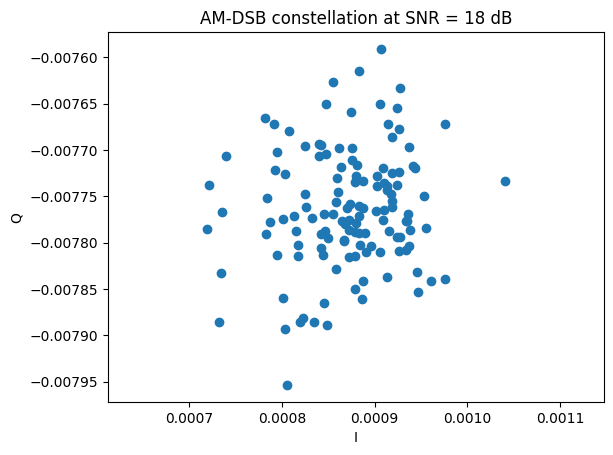

In [10]:
example_array2 = data[('AM-DSB', 18)]
example2 = example_array2[0]
I2 = example2[0]
Q2 = example2[1]

plt.scatter(I2, Q2)
plt.xlabel("I")
plt.ylabel("Q")
plt.title("AM-DSB constellation at SNR = 18 dB")
plt.axis("equal")
plt.show()

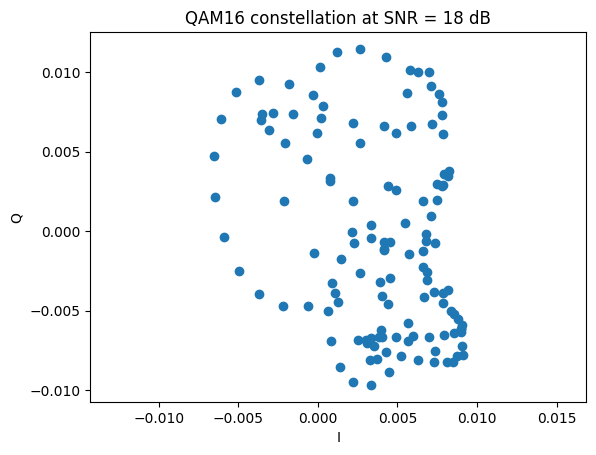

In [11]:
example_array3 = data[('QAM16', 18)]
example3 = example_array3[0]
I3 = example3[0]
Q3 = example3[1]

plt.scatter(I3, Q3)
plt.xlabel("I")
plt.ylabel("Q")
plt.title("QAM16 constellation at SNR = 18 dB")
plt.axis("equal")
plt.show()

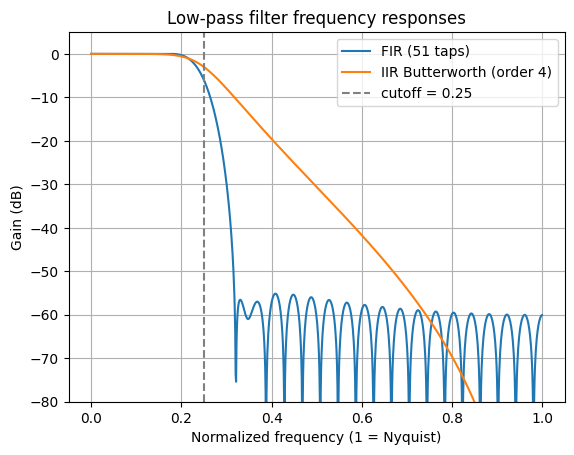

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

cutoff = 0.25   # fraction of Nyquist (assumption, as discussed)

# Design both filters
fir_coeffs = signal.firwin(51, cutoff)
iir_b, iir_a = signal.butter(4, cutoff)

# Frequency responses
w_fir, h_fir = signal.freqz(fir_coeffs, 1, worN=1024)
w_iir, h_iir = signal.freqz(iir_b, iir_a, worN=1024)

# Convert to fraction of Nyquist (0 to 1) and gain in dB
f_fir = w_fir / np.pi
f_iir = w_iir / np.pi
gain_fir_db = 20 * np.log10(np.abs(h_fir) + 1e-12)
gain_iir_db = 20 * np.log10(np.abs(h_iir) + 1e-12)

plt.plot(f_fir, gain_fir_db, label="FIR (51 taps)")
plt.plot(f_iir, gain_iir_db, label="IIR Butterworth (order 4)")
plt.axvline(cutoff, color="gray", linestyle="--", label="cutoff = 0.25")
plt.ylim(-80, 5)
plt.xlabel("Normalized frequency (1 = Nyquist)")
plt.ylabel("Gain (dB)")
plt.title("Low-pass filter frequency responses")
plt.legend()
plt.grid(True)
plt.show()

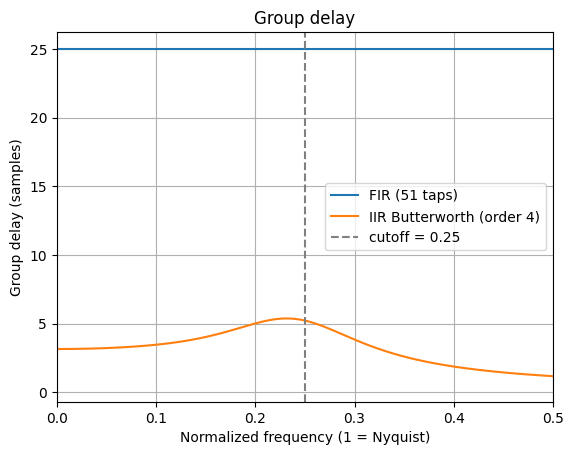

In [13]:
w_fir_gd, gd_fir = signal.group_delay((fir_coeffs, [1.0]), w=1024)
w_iir_gd, gd_iir = signal.group_delay((iir_b, iir_a), w=1024)

f_gd = w_fir_gd / np.pi   # fraction of Nyquist, same axis as before

plt.plot(f_gd, gd_fir, label="FIR (51 taps)")
plt.plot(f_gd, gd_iir, label="IIR Butterworth (order 4)")
plt.axvline(cutoff, color="gray", linestyle="--", label="cutoff = 0.25")
plt.xlim(0, 0.5)
plt.xlabel("Normalized frequency (1 = Nyquist)")
plt.ylabel("Group delay (samples)")
plt.title("Group delay")
plt.legend()
plt.grid(True)
plt.show()

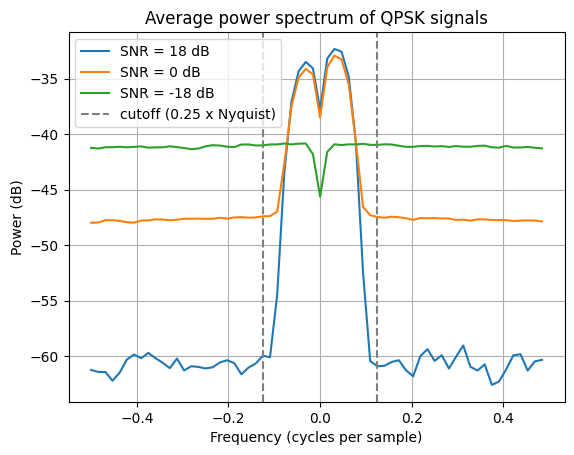

In [18]:
def avg_psd(mod, snr):
    arr = data[(mod, snr)]                    # shape (1000, 2, 128)
    sig_all = arr[:, 0, :] + 1j * arr[:, 1, :]   # complex signal, shape (1000, 128)
    f, p = signal.welch(sig_all, nperseg=64, axis=-1, return_onesided=False)
    f = np.fft.fftshift(f)
    p = np.fft.fftshift(p, axes=-1)
    return f, 10 * np.log10(p.mean(axis=0))   # average over the 1000 examples

for snr in [18, 0, -18]:
    f, p_db = avg_psd('QPSK', snr)
    plt.plot(f, p_db, label=f"SNR = {snr} dB")

plt.axvline(0.125, color="gray", linestyle="--", label="cutoff (0.25 x Nyquist)")
plt.axvline(-0.125, color="gray", linestyle="--")
plt.xlabel("Frequency (cycles per sample)")
plt.ylabel("Power (dB)")
plt.title("Average power spectrum of QPSK signals")
plt.legend()
plt.grid(True)
plt.show()

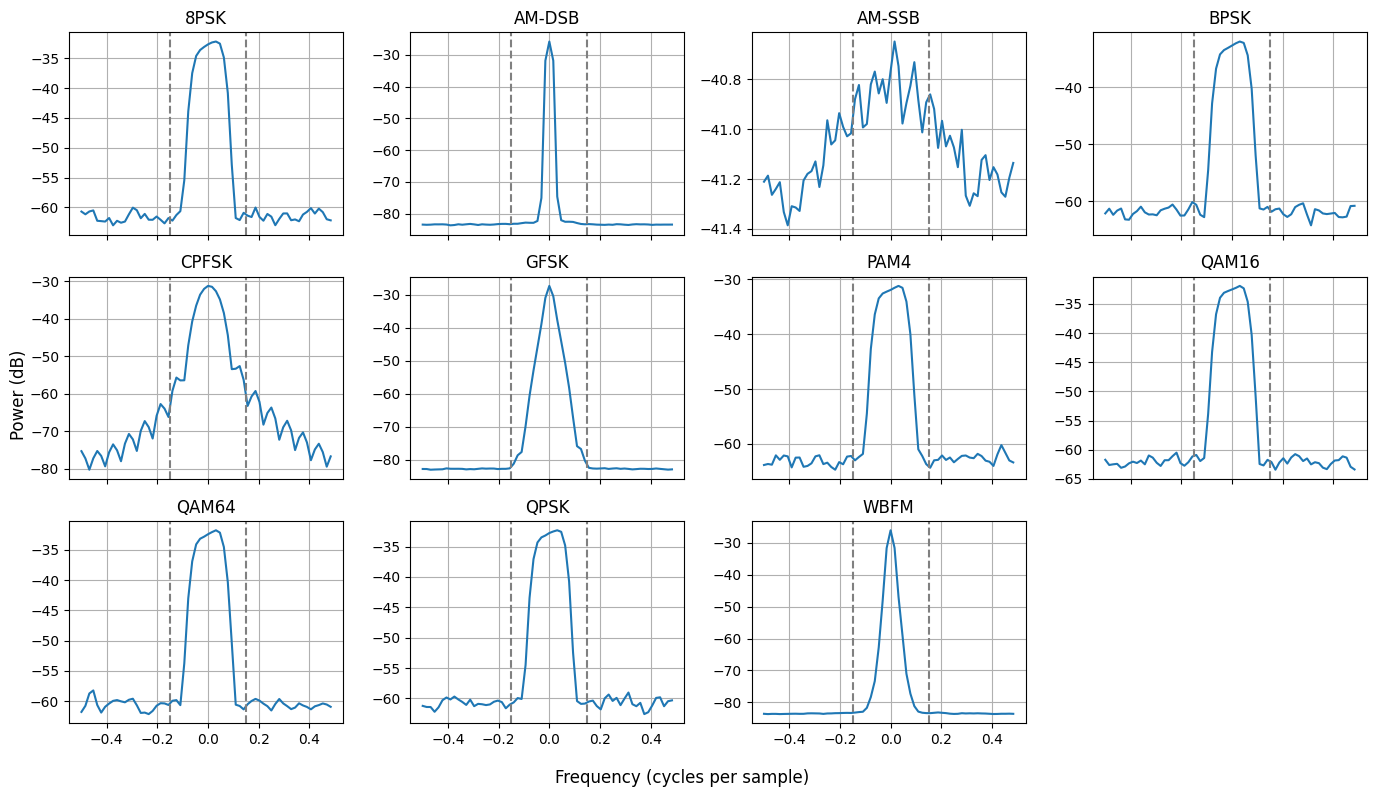

In [19]:
mod_types = sorted(set(k[0] for k in data.keys()))

def avg_psd(mod, snr, detrend=False):
    arr = data[(mod, snr)]
    sig_all = arr[:, 0, :] + 1j * arr[:, 1, :]
    f, p = signal.welch(sig_all, nperseg=64, axis=-1,
                        return_onesided=False, detrend=detrend)
    f = np.fft.fftshift(f)
    p = np.fft.fftshift(p, axes=-1)
    return f, 10 * np.log10(p.mean(axis=0))

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
axes = axes.ravel()
for ax, mod in zip(axes, mod_types):
    f, p_db = avg_psd(mod, 18)
    ax.plot(f, p_db)
    ax.axvline(0.15, color="gray", linestyle="--")
    ax.axvline(-0.15, color="gray", linestyle="--")
    ax.set_title(mod)
    ax.grid(True)
axes[-1].axis("off")
fig.supxlabel("Frequency (cycles per sample)")
fig.supylabel("Power (dB)")
plt.tight_layout()
plt.show()

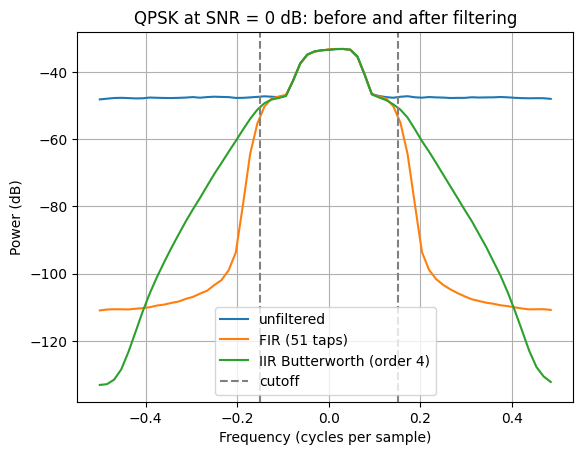

In [20]:
cutoff = 0.3
fir_coeffs = signal.firwin(51, cutoff)
iir_b, iir_a = signal.butter(4, cutoff)

arr = data[('QPSK', 0)]
x = arr[:, 0, :] + 1j * arr[:, 1, :]      # shape (1000, 128), complex

y_fir = signal.lfilter(fir_coeffs, 1.0, x, axis=-1)
y_iir = signal.lfilter(iir_b, iir_a, x, axis=-1)

def psd_db(sig_2d):
    f, p = signal.welch(sig_2d, nperseg=64, axis=-1,
                        return_onesided=False, detrend=False)
    return np.fft.fftshift(f), 10 * np.log10(np.fft.fftshift(p, axes=-1).mean(axis=0))

# skip the first 64 samples (start-up transient); apply the same slice to all three
f, p_raw = psd_db(x[:, 64:])
_, p_fir = psd_db(y_fir[:, 64:])
_, p_iir = psd_db(y_iir[:, 64:])

plt.plot(f, p_raw, label="unfiltered")
plt.plot(f, p_fir, label="FIR (51 taps)")
plt.plot(f, p_iir, label="IIR Butterworth (order 4)")
plt.axvline(0.15, color="gray", linestyle="--", label="cutoff")
plt.axvline(-0.15, color="gray", linestyle="--")
plt.xlabel("Frequency (cycles per sample)")
plt.ylabel("Power (dB)")
plt.title("QPSK at SNR = 0 dB: before and after filtering")
plt.legend()
plt.grid(True)
plt.show()

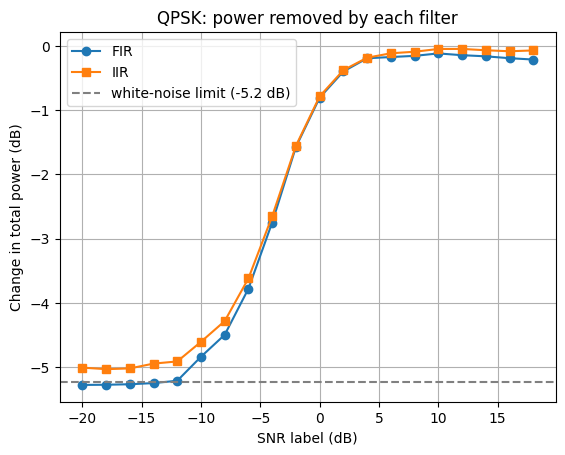

In [21]:
snr_levels = sorted(set(k[1] for k in data.keys()))

def total_power_db(sig_2d):
    return 10 * np.log10(np.mean(np.abs(sig_2d) ** 2))

fir_change = []
iir_change = []

for snr in snr_levels:
    arr = data[('QPSK', snr)]
    x = arr[:, 0, :] + 1j * arr[:, 1, :]
    y_f = signal.lfilter(fir_coeffs, 1.0, x, axis=-1)
    y_i = signal.lfilter(iir_b, iir_a, x, axis=-1)
    p0 = total_power_db(x[:, 64:])
    fir_change.append(total_power_db(y_f[:, 64:]) - p0)
    iir_change.append(total_power_db(y_i[:, 64:]) - p0)

plt.plot(snr_levels, fir_change, marker="o", label="FIR")
plt.plot(snr_levels, iir_change, marker="s", label="IIR")
plt.axhline(10 * np.log10(0.3), color="gray", linestyle="--",
            label="white-noise limit (-5.2 dB)")
plt.xlabel("SNR label (dB)")
plt.ylabel("Change in total power (dB)")
plt.title("QPSK: power removed by each filter")
plt.legend()
plt.grid(True)
plt.show()

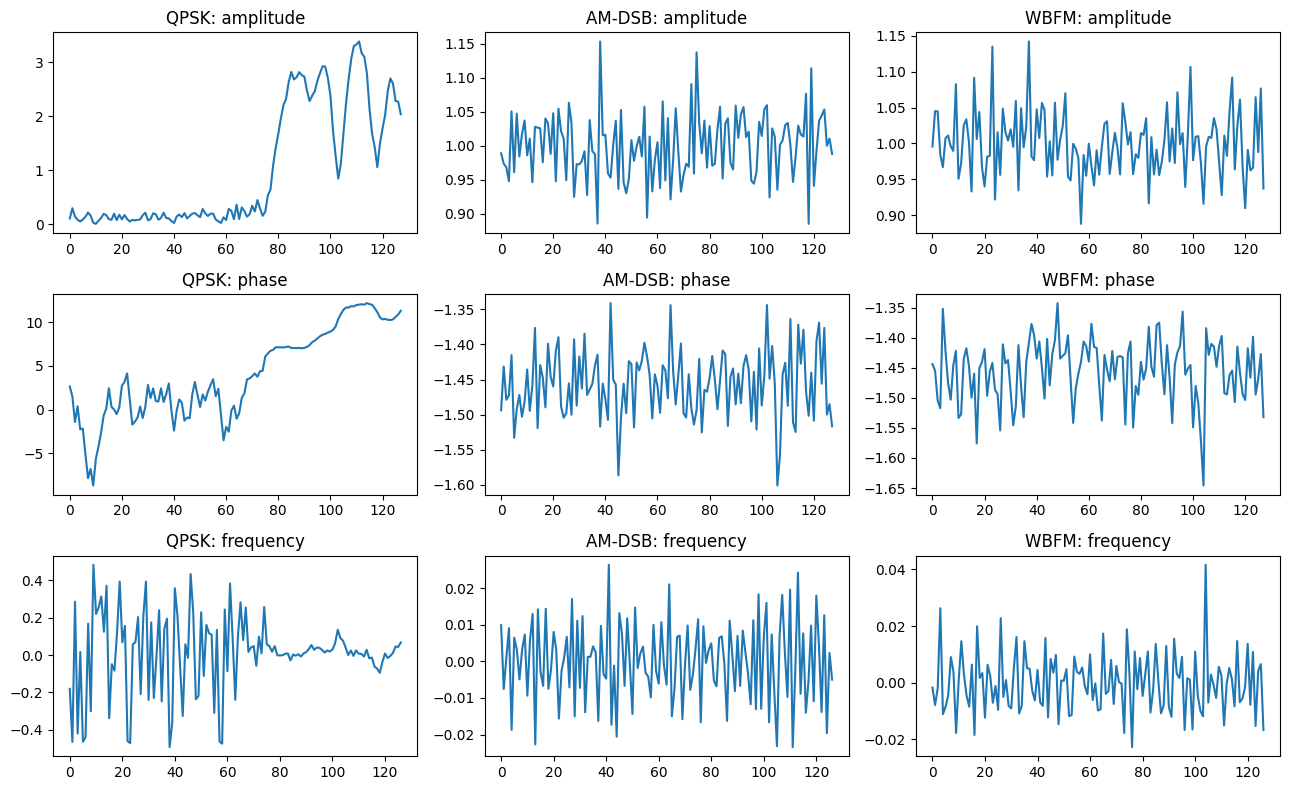

In [22]:
mods_to_show = ['QPSK', 'AM-DSB', 'WBFM']
fig, axes = plt.subplots(3, 3, figsize=(13, 8))

for col, mod in enumerate(mods_to_show):
    arr = data[(mod, 10)]
    x = arr[0, 0, :] + 1j * arr[0, 1, :]      # first example, complex, 128 samples

    amp = np.abs(x)
    amp = amp / amp.mean()                     # remove the arbitrary overall scale
    phase = np.unwrap(np.angle(x))             # radians, made continuous
    freq = np.diff(phase) / (2 * np.pi)        # cycles per sample, 127 values

    axes[0, col].plot(amp)
    axes[0, col].set_title(f"{mod}: amplitude")
    axes[1, col].plot(phase)
    axes[1, col].set_title(f"{mod}: phase")
    axes[2, col].plot(freq)
    axes[2, col].set_title(f"{mod}: frequency")

plt.tight_layout()
plt.show()

QPSK second half / first half: 1.03
BPSK second half / first half: 1.02
QAM16 second half / first half: 1.03
AM-DSB second half / first half: 1.0
AM-SSB second half / first half: 1.0
WBFM second half / first half: 1.0


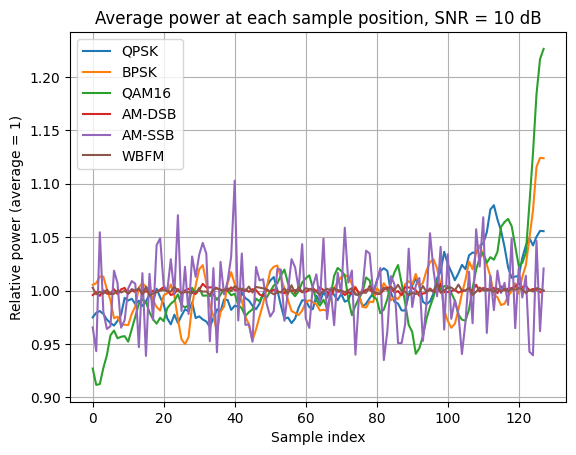

In [23]:
mods_check = ['QPSK', 'BPSK', 'QAM16', 'AM-DSB', 'AM-SSB', 'WBFM']

for mod in mods_check:
    arr = data[(mod, 10)]
    x = arr[:, 0, :] + 1j * arr[:, 1, :]           # shape (1000, 128)
    profile = (np.abs(x) ** 2).mean(axis=0)         # average power at each sample, shape (128,)
    profile = profile / profile.mean()              # scale so the overall average is 1
    plt.plot(profile, label=mod)
    print(mod, "second half / first half:",
          round(profile[64:].mean() / profile[:64].mean(), 2))

plt.xlabel("Sample index")
plt.ylabel("Relative power (average = 1)")
plt.title("Average power at each sample position, SNR = 10 dB")
plt.legend()
plt.grid(True)
plt.show()

QPSK median |imbalance| (dB): 0.22  90th percentile: 0.57
BPSK median |imbalance| (dB): 0.19  90th percentile: 0.53
QAM16 median |imbalance| (dB): 0.8  90th percentile: 2.03
AM-DSB median |imbalance| (dB): 0.05  90th percentile: 0.11
AM-SSB median |imbalance| (dB): 0.59  90th percentile: 1.36
WBFM median |imbalance| (dB): 0.05  90th percentile: 0.11


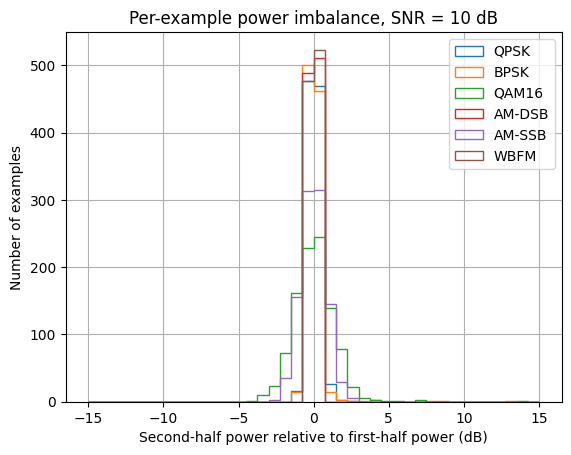

In [24]:
mods_check = ['QPSK', 'BPSK', 'QAM16', 'AM-DSB', 'AM-SSB', 'WBFM']

for mod in mods_check:
    arr = data[(mod, 10)]
    x = arr[:, 0, :] + 1j * arr[:, 1, :]           # shape (1000, 128)
    p = np.abs(x) ** 2
    first = p[:, :64].mean(axis=1)                  # one number per example, shape (1000,)
    second = p[:, 64:].mean(axis=1)
    ratio_db = 10 * np.log10(second / first)        # 0 dB = equal power in both halves

    print(mod, "median |imbalance| (dB):", round(np.median(np.abs(ratio_db)), 2),
          " 90th percentile:", round(np.percentile(np.abs(ratio_db), 90), 2))
    plt.hist(ratio_db, bins=40, range=(-15, 15), histtype="step", label=mod)

plt.xlabel("Second-half power relative to first-half power (dB)")
plt.ylabel("Number of examples")
plt.title("Per-example power imbalance, SNR = 10 dB")
plt.legend()
plt.grid(True)
plt.show()


In [25]:
for mod in mods_check:
    arr = data[(mod, 10)]
    x = arr[:, 0, :] + 1j * arr[:, 1, :]
    p = np.abs(x) ** 2
    ratio_db = 10 * np.log10(p[:, 64:].mean(axis=1) / p[:, :64].mean(axis=1))

    n_big = np.sum(np.abs(ratio_db) > 3)
    worst = np.argmax(np.abs(ratio_db))
    print(mod, "| examples above 3 dB:", n_big,
          "| example 0:", round(ratio_db[0], 1), "dB",
          "| largest:", round(ratio_db[worst], 1), "dB at index", worst)

QPSK | examples above 3 dB: 7 | example 0: 23.2 dB | largest: 23.2 dB at index 0
BPSK | examples above 3 dB: 6 | example 0: 0.5 dB | largest: 21.0 dB at index 431
QAM16 | examples above 3 dB: 28 | example 0: 7.0 dB | largest: 30.4 dB at index 424
AM-DSB | examples above 3 dB: 0 | example 0: 0.1 dB | largest: 0.2 dB at index 486
AM-SSB | examples above 3 dB: 0 | example 0: -1.1 dB | largest: 2.7 dB at index 323
WBFM | examples above 3 dB: 0 | example 0: -0.0 dB | largest: -0.2 dB at index 699
